# 01 · Indra — historical financial data

**Goal:** turn Indra's investor-relations Excel files into one clean dataset, reconcile it with the figures Indra published, and take a first look at the business.

**Sources:** `data/raw/` (one Excel file per period, see `data/README.md`). The loading logic lives in `src/data.py`; this notebook uses it and documents the findings.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent          # the notebook runs from notebooks/, the project root is one level up
sys.path.append(str(ROOT))        # lets us import our own code from src/

import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_long, key_metrics

pd.set_option("display.float_format", "{:,.1f}".format)

## 1. Load every statement in tidy (long) format

One row per `period × statement × line item`. `PL` = profit & loss, `BS` = balance sheet, `CF` = cash flow. Units: EUR millions.

In [2]:
long = load_long()
print(long.shape)
long.head(10)

(613, 6)


,period,statement,line_item,value,unit,source
0,2019,PL,Revenue,"3,203.9",EUR m,pg_bs_cf_fy19_eng_web-envio.xls
1,2019,PL,In-house work on non-current assets and other ...,90.9,EUR m,pg_bs_cf_fy19_eng_web-envio.xls
2,2019,PL,Materials used and other supplies and other op...,"-1,189.5",EUR m,pg_bs_cf_fy19_eng_web-envio.xls
3,2019,PL,Staff Costs,"-1,757.7",EUR m,pg_bs_cf_fy19_eng_web-envio.xls
4,2019,PL,Other gains or losses on non-current assets an...,-1.4,EUR m,pg_bs_cf_fy19_eng_web-envio.xls
5,2019,PL,Gross Operating Profit (EBITDA),346.2,EUR m,pg_bs_cf_fy19_eng_web-envio.xls
6,2019,PL,Depreciation and amortisation charge,-125.2,EUR m,pg_bs_cf_fy19_eng_web-envio.xls
7,2019,PL,Profit (Loss) from operations (EBIT),221.0,EUR m,pg_bs_cf_fy19_eng_web-envio.xls
8,2019,PL,EBIT Margin,0.1,EUR m,pg_bs_cf_fy19_eng_web-envio.xls
9,2019,PL,Financial Loss,-44.2,EUR m,pg_bs_cf_fy19_eng_web-envio.xls


## 2. Three traps found in the raw files

1. **Labels change over time.** The same metric has different names in different years (e.g. EBITDA below). `src/data.py` maps every label to one canonical name (`METRIC_MAP`).
2. **The sign convention of net debt flipped in 2024.** Until FY2023 debt was reported as a negative number; from FY2024 it is positive (`Net Debt (+) / Net Cash (-)`). We use the modern convention everywhere: **positive = net debt, negative = net cash**.
3. **Gaps and partial periods.** There is no FY2022 Excel file (it will be taken from the audited 2022 accounts), and `9M2026` covers only nine months.

In [3]:
# Trap 1: the EBITDA line has two different names across the years
long[long["line_item"].str.contains("EBITDA")][["period", "line_item", "value"]]

,period,line_item,value
5,2019,Gross Operating Profit (EBITDA),346.2
88,2020,Gross Operating Profit (EBITDA),77.4
171,2021,Gross Operating Result (EBITDA),349.1
255,2023,Gross Operating Result (EBITDA),446.1
339,2024,Gross Operating Result (EBITDA),545.2
432,2025,Gross Operating Result (EBITDA),636.4
525,9M2026,Gross Operating Result (EBITDA),657.4


In [4]:
# Trap 2: the same 'Final Net Debt' line, before harmonising signs
long[long["line_item"] == "Final Net Debt"][["period", "value"]]

,period,value
82,2019,-551.8
165,2020,-481.4
249,2021,-240.4
333,2023,-106.8
419,2024,-86.5
512,2025,583.2
605,9M2026,"-1,192.2"


## 3. Key metrics with consistent names and signs

In [5]:
metrics = key_metrics(long)
metrics.T

period,2019,2020,2021,2023,2024,2025,9M2026
metric,,,,,,,
revenue,"3,203.9","3,043.4","3,390.4","4,343.1","4,842.9","5,456.7","4,644.7"
ebitda,346.2,77.4,349.1,446.1,545.2,636.4,657.4
d_and_a,-125.2,-110.3,-93.5,-99.1,-106.9,-119.0,-203.8
ebit,221.0,-32.9,255.5,347.0,438.3,517.3,453.6
profit_before_tax,177.6,-72.4,211.4,303.6,386.3,586.3,488.1
income_tax,-51.5,14.9,-65.4,-94.9,-106.0,-147.3,-120.0
minorities_profit,-4.7,-7.7,-2.7,-2.9,-2.7,-3.1,-12.7
net_profit,121.4,-65.2,143.4,205.8,277.5,435.8,355.5
change_receivables,36.9,186.3,19.5,37.3,110.1,-314.3,"1,441.9"


## 4. Reconciliation with published figures

Before using any number, check it against what the company published. Indra's FY2025 results: revenue €5,457m, EBITDA €636m, EBIT €517m, free cash flow €364m, net debt €583m (net cash of €86m at the end of 2024).

In [6]:
published_2025 = {"revenue": 5457, "ebitda": 636, "ebit": 517, "fcf_reported": 364, "net_debt": 583}

check = pd.DataFrame({
    "published": published_2025,
    "from_excel": metrics.loc["2025", list(published_2025)].astype(float),
})
check["difference"] = check["from_excel"] - check["published"]
check

,published,from_excel,difference
revenue,5457,"5,456.7",-0.3
ebitda,636,636.4,0.4
ebit,517,517.3,0.3
fcf_reported,364,364.3,0.3
net_debt,583,583.2,0.2


In [7]:
# Internal consistency: EBITDA + D&A (negative in the P&L) must equal EBIT in every period
(metrics["ebitda"] + metrics["d_and_a"] - metrics["ebit"]).abs().max()

np.float64(0.0)

## 5. First look at the business (full years only)

- **Revenue growth.** 2021→2023 spans two years (FY2022 is missing), so growth is annualised: $g = (R_t / R_s)^{1/(t-s)} - 1$.
- **EBIT margin** = EBIT / revenue.
- **Capex intensity** = capex / revenue.
- **Change in working capital** = receivables + inventories + payables lines of the cash flow (negative = cash absorbed).

In [8]:
full = metrics[metrics["is_full_year"]].copy()
years = full.index.astype(int)

full["revenue_growth"] = (full["revenue"] / full["revenue"].shift(1)) ** (1 / (years - years.to_series().shift(1).values)) - 1
full["ebit_margin"] = full["ebit"] / full["revenue"]
full["capex_to_revenue"] = -full["capex"] / full["revenue"]
full["change_nwc"] = full[["change_receivables", "change_inventories", "change_payables"]].sum(axis=1)

ratios = full[["revenue", "revenue_growth", "ebit_margin", "capex_to_revenue", "change_nwc", "fcf_reported"]]
ratios.style.format({
    "revenue": "{:,.0f}", "revenue_growth": "{:.1%}", "ebit_margin": "{:.1%}",
    "capex_to_revenue": "{:.1%}", "change_nwc": "{:,.0f}", "fcf_reported": "{:,.0f}",
})

metric,revenue,revenue_growth,ebit_margin,capex_to_revenue,change_nwc,fcf_reported
period,,,,,,
2019,"3,204",nan%,6.9%,2.4%,-131,8
2020,"3,043",-5.0%,-1.1%,1.3%,43,83
2021,"3,390",11.4%,7.5%,-0.3%,55,289
2023,"4,343",13.2%,8.0%,0.4%,14,312
2024,"4,843",11.5%,9.0%,1.4%,-5,328
2025,"5,457",12.7%,9.5%,1.8%,63,364


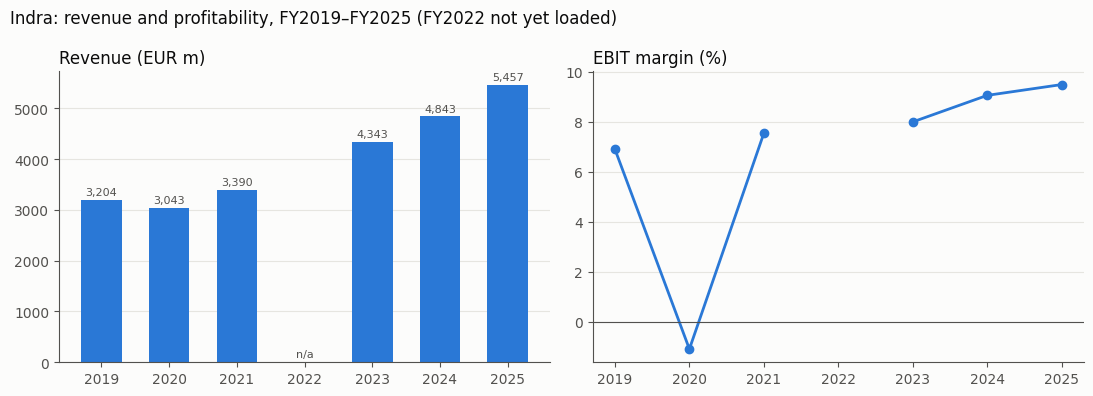

In [9]:
BLUE, INK, MUTED, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#fcfcfb"

# Put the years on a numeric axis and leave 2022 empty, so the missing year is visible
plot = full.set_index(years).reindex(range(2019, 2026))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), facecolor=SURFACE)

ax1.bar(plot.index, plot["revenue"], color=BLUE, width=0.6)
ax1.set_title("Revenue (EUR m)", loc="left", color=INK)
for x, v in plot["revenue"].items():
    label = "n/a" if pd.isna(v) else f"{v:,.0f}"
    ax1.annotate(label, (x, 0 if pd.isna(v) else v), ha="center", va="bottom", fontsize=8, color=MUTED, xytext=(0, 2), textcoords="offset points")

ax2.plot(plot.index, plot["ebit_margin"] * 100, color=BLUE, linewidth=2, marker="o", markersize=6)
ax2.set_title("EBIT margin (%)", loc="left", color=INK)
ax2.axhline(0, color=MUTED, linewidth=0.8)

for ax in (ax1, ax2):
    ax.set_facecolor(SURFACE)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(MUTED)
    ax.tick_params(colors=MUTED)
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_xticks(range(2019, 2026))

fig.suptitle("Indra: revenue and profitability, FY2019–FY2025 (FY2022 not yet loaded)", x=0.01, ha="left", color=INK)
fig.tight_layout()
(ROOT / "reports" / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT / "reports" / "figures" / "01_revenue_ebit_margin.png", dpi=150, facecolor=SURFACE)
plt.show()

## 6. What the data already tells us

- **2020 (COVID):** revenue fell ~5% and EBIT turned negative, so the margin is not a stable constant. This history is evidence that drivers must be modelled as random variables, with fat left tails.
- **Margin expansion:** EBIT margin rose steadily after 2020, as the mix shifted towards defence and air traffic.
- **2025 is a break in the balance sheet:** property, plant & equipment and minorities jump (Hispasat, TESS), and net debt turns positive after €808m of acquisitions.
- **9M2026 free cash flow (€1,692m) is not representative:** it is driven by customer advances (receivables line +€1,442m). It must be normalised, not extrapolated.
- **Reported FCF ≠ FCFF:** Indra's free cash flow is *after* interest paid, so it is not the textbook FCFF used in the DCF. We rebuild FCFF in phase 2.

**Open items:** load FY2022 from the audited accounts; add segment revenue and order backlog from the quarterly reports.

## 7. Save the processed data

In [10]:
out = ROOT / "data" / "processed"
long.to_csv(out / "indra_financials_long.csv", index=False)
metrics.to_csv(out / "indra_key_metrics.csv")
sorted(p.name for p in out.glob("*.csv"))

['indra_financials_long.csv', 'indra_key_metrics.csv']